# Data Loading

In [ ]:
import pandas as pd

df = pd.read_csv('../data/match_features.csv')
df_all = df.drop(columns=['nation', "match_no", "stage"])
df_group_stage = df[df['stage'] == 'group stage'].drop(columns=['nation', "match_no", "stage"])
df_knockout = df[df['stage'] == 'knock out'].drop(columns=['nation', "match_no", "stage"])

# df_all.to_csv('../data/data_all.csv', index=False)
# df_group_stage.to_csv('../data/data_group_stage.csv', index=False)
# df_knockout.to_csv('../data/data_knock_out.csv', index=False)

# Classification

## Data Loading and Model Training

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("../data/data_all.csv")

# Target column
target = "win"

df["outcome"] = df["win"].map({
    0: 0,      # lose
    0.5: 1,    # draw
    1: 2       # win
})

# Features and target
X = df.drop(columns=["win", "outcome"])
y = df["outcome"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Train target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("Test target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Train shape: (176, 131)
Test shape: (32, 131)
Train target distribution:
outcome
0    0.386364
1    0.227273
2    0.386364
Name: proportion, dtype: float64
Test target distribution:
outcome
0    0.375
1    0.250
2    0.375
Name: proportion, dtype: float64


C:\Users\Administrator\AppData\Local\Temp\ipykernel_18420\1056238592.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["outcome"] = df["win"].map({


In [2]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.04,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,

    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",

    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) r

Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

        lose     0.6667    0.8333    0.7407        12
        draw     1.0000    0.2500    0.4000         8
         win     0.8000    1.0000    0.8889        12

    accuracy                         0.7500        32
   macro avg     0.8222    0.6944    0.6765        32
weighted avg     0.8000    0.7500    0.7111        32



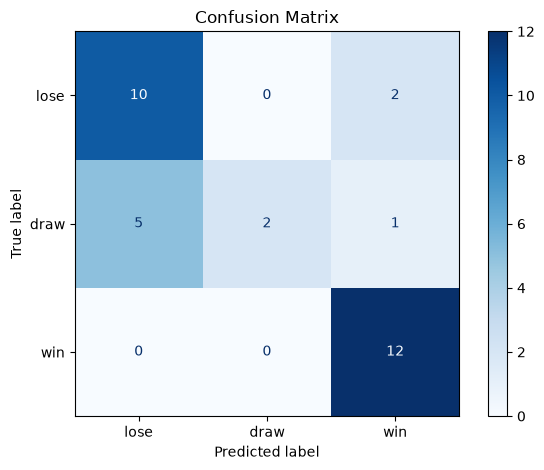

In [3]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict classes
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["lose", "draw", "win"],
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["lose", "draw", "win"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [4]:
import shap

# Create explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer(X_test)

print(shap_values.shape)

e:\miniconda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(32, 131, 3)


## Win Feature Shap

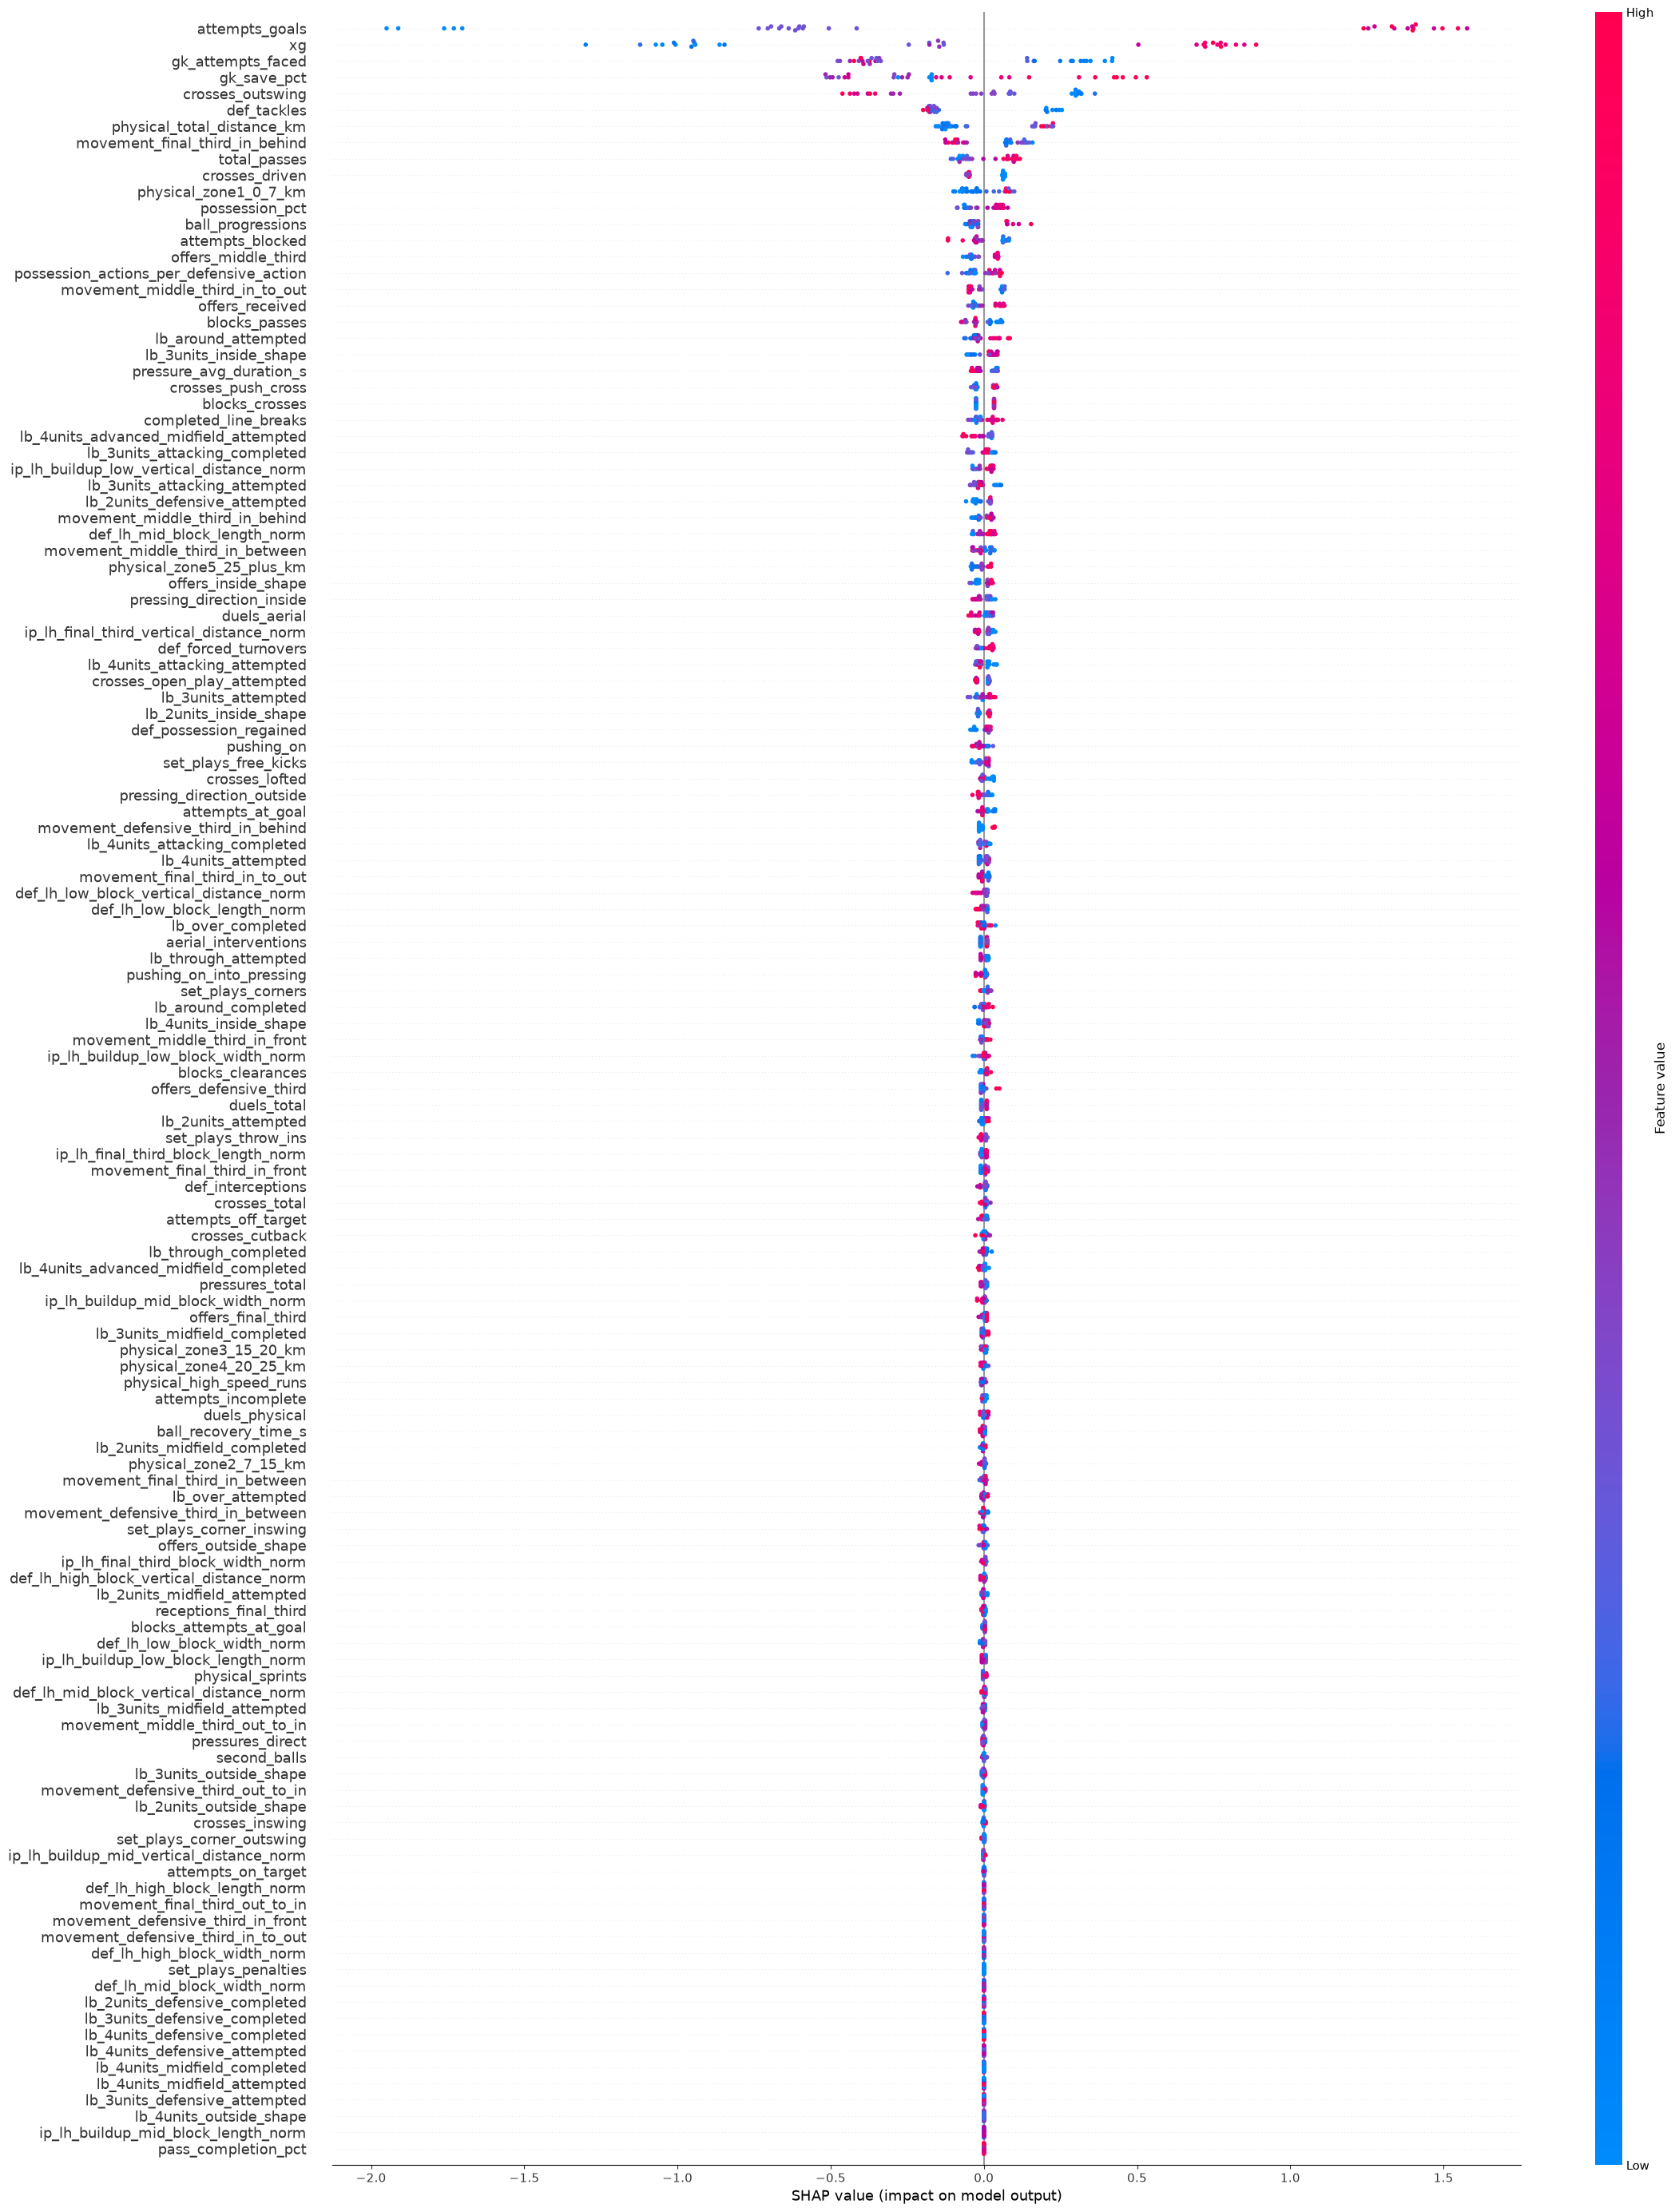

In [39]:
shap.plots.beeswarm(
    shap_values[:, :, 2],
    max_display=200,
    plot_size=(24, 35),
)

## Lose Feature Shap

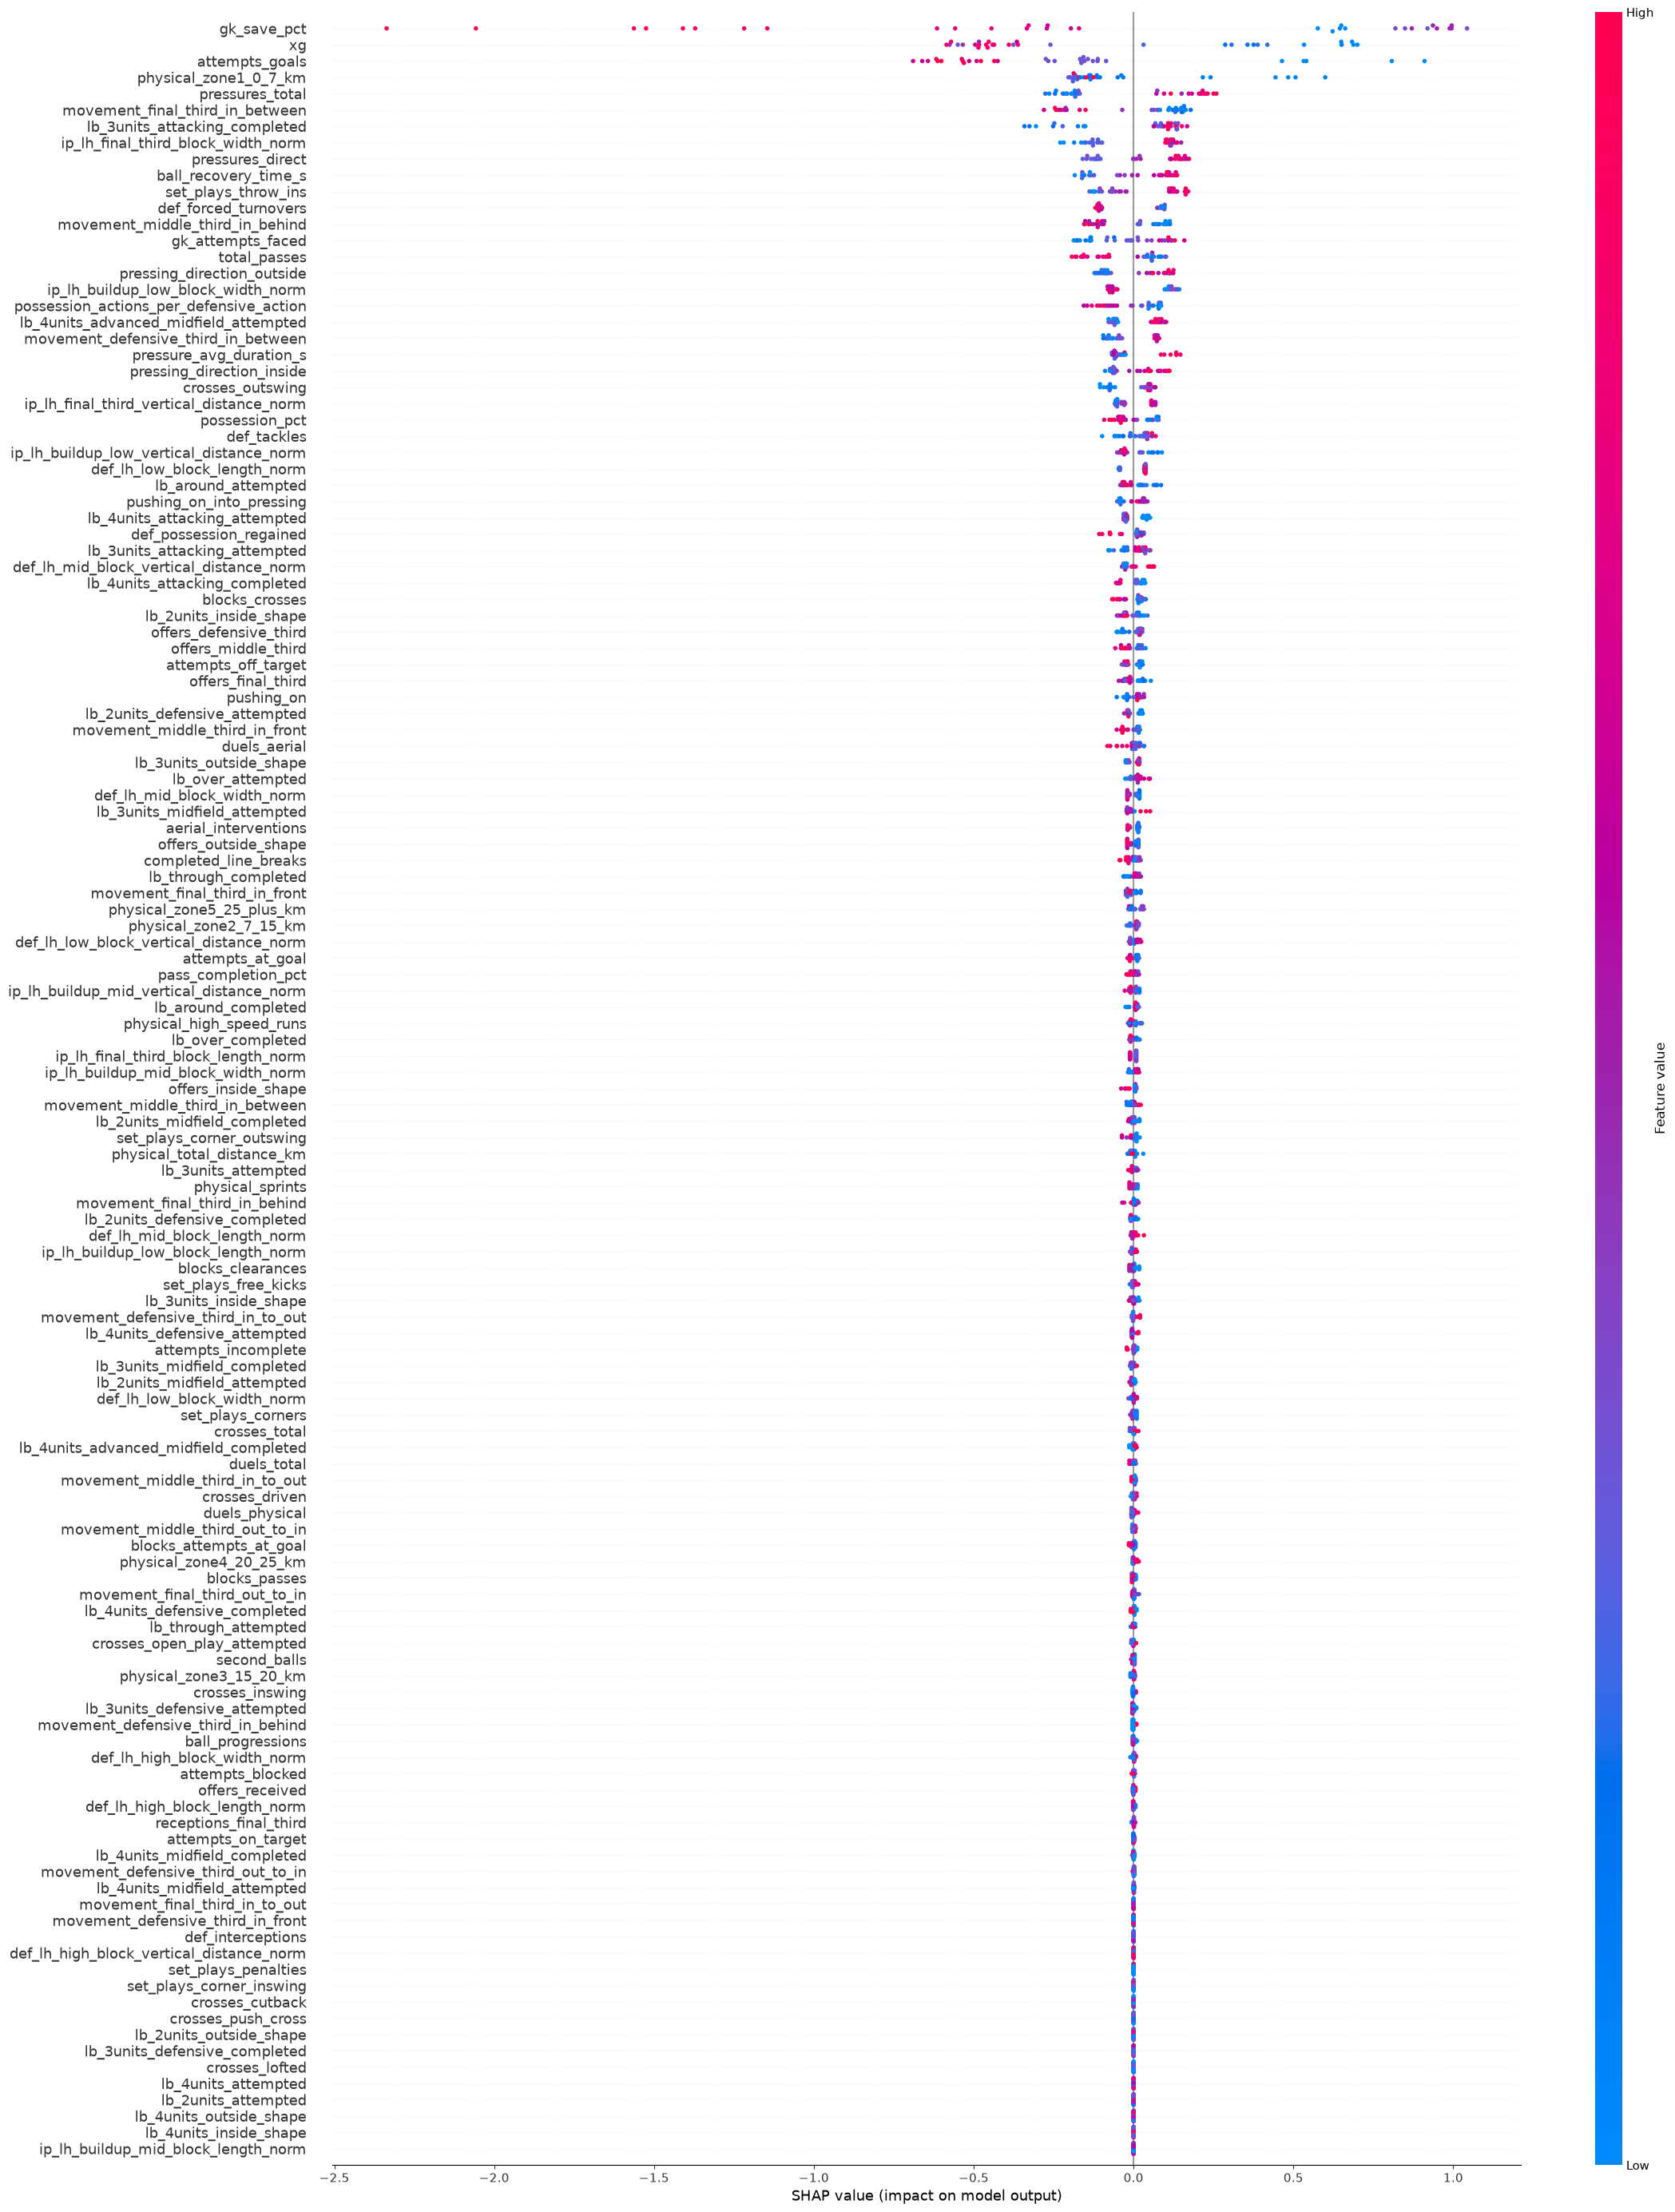

In [5]:
shap.plots.beeswarm(
    shap_values[:, :, 0],
    max_display=200,
    plot_size=(24, 35),
)

## Draw Feature Shap

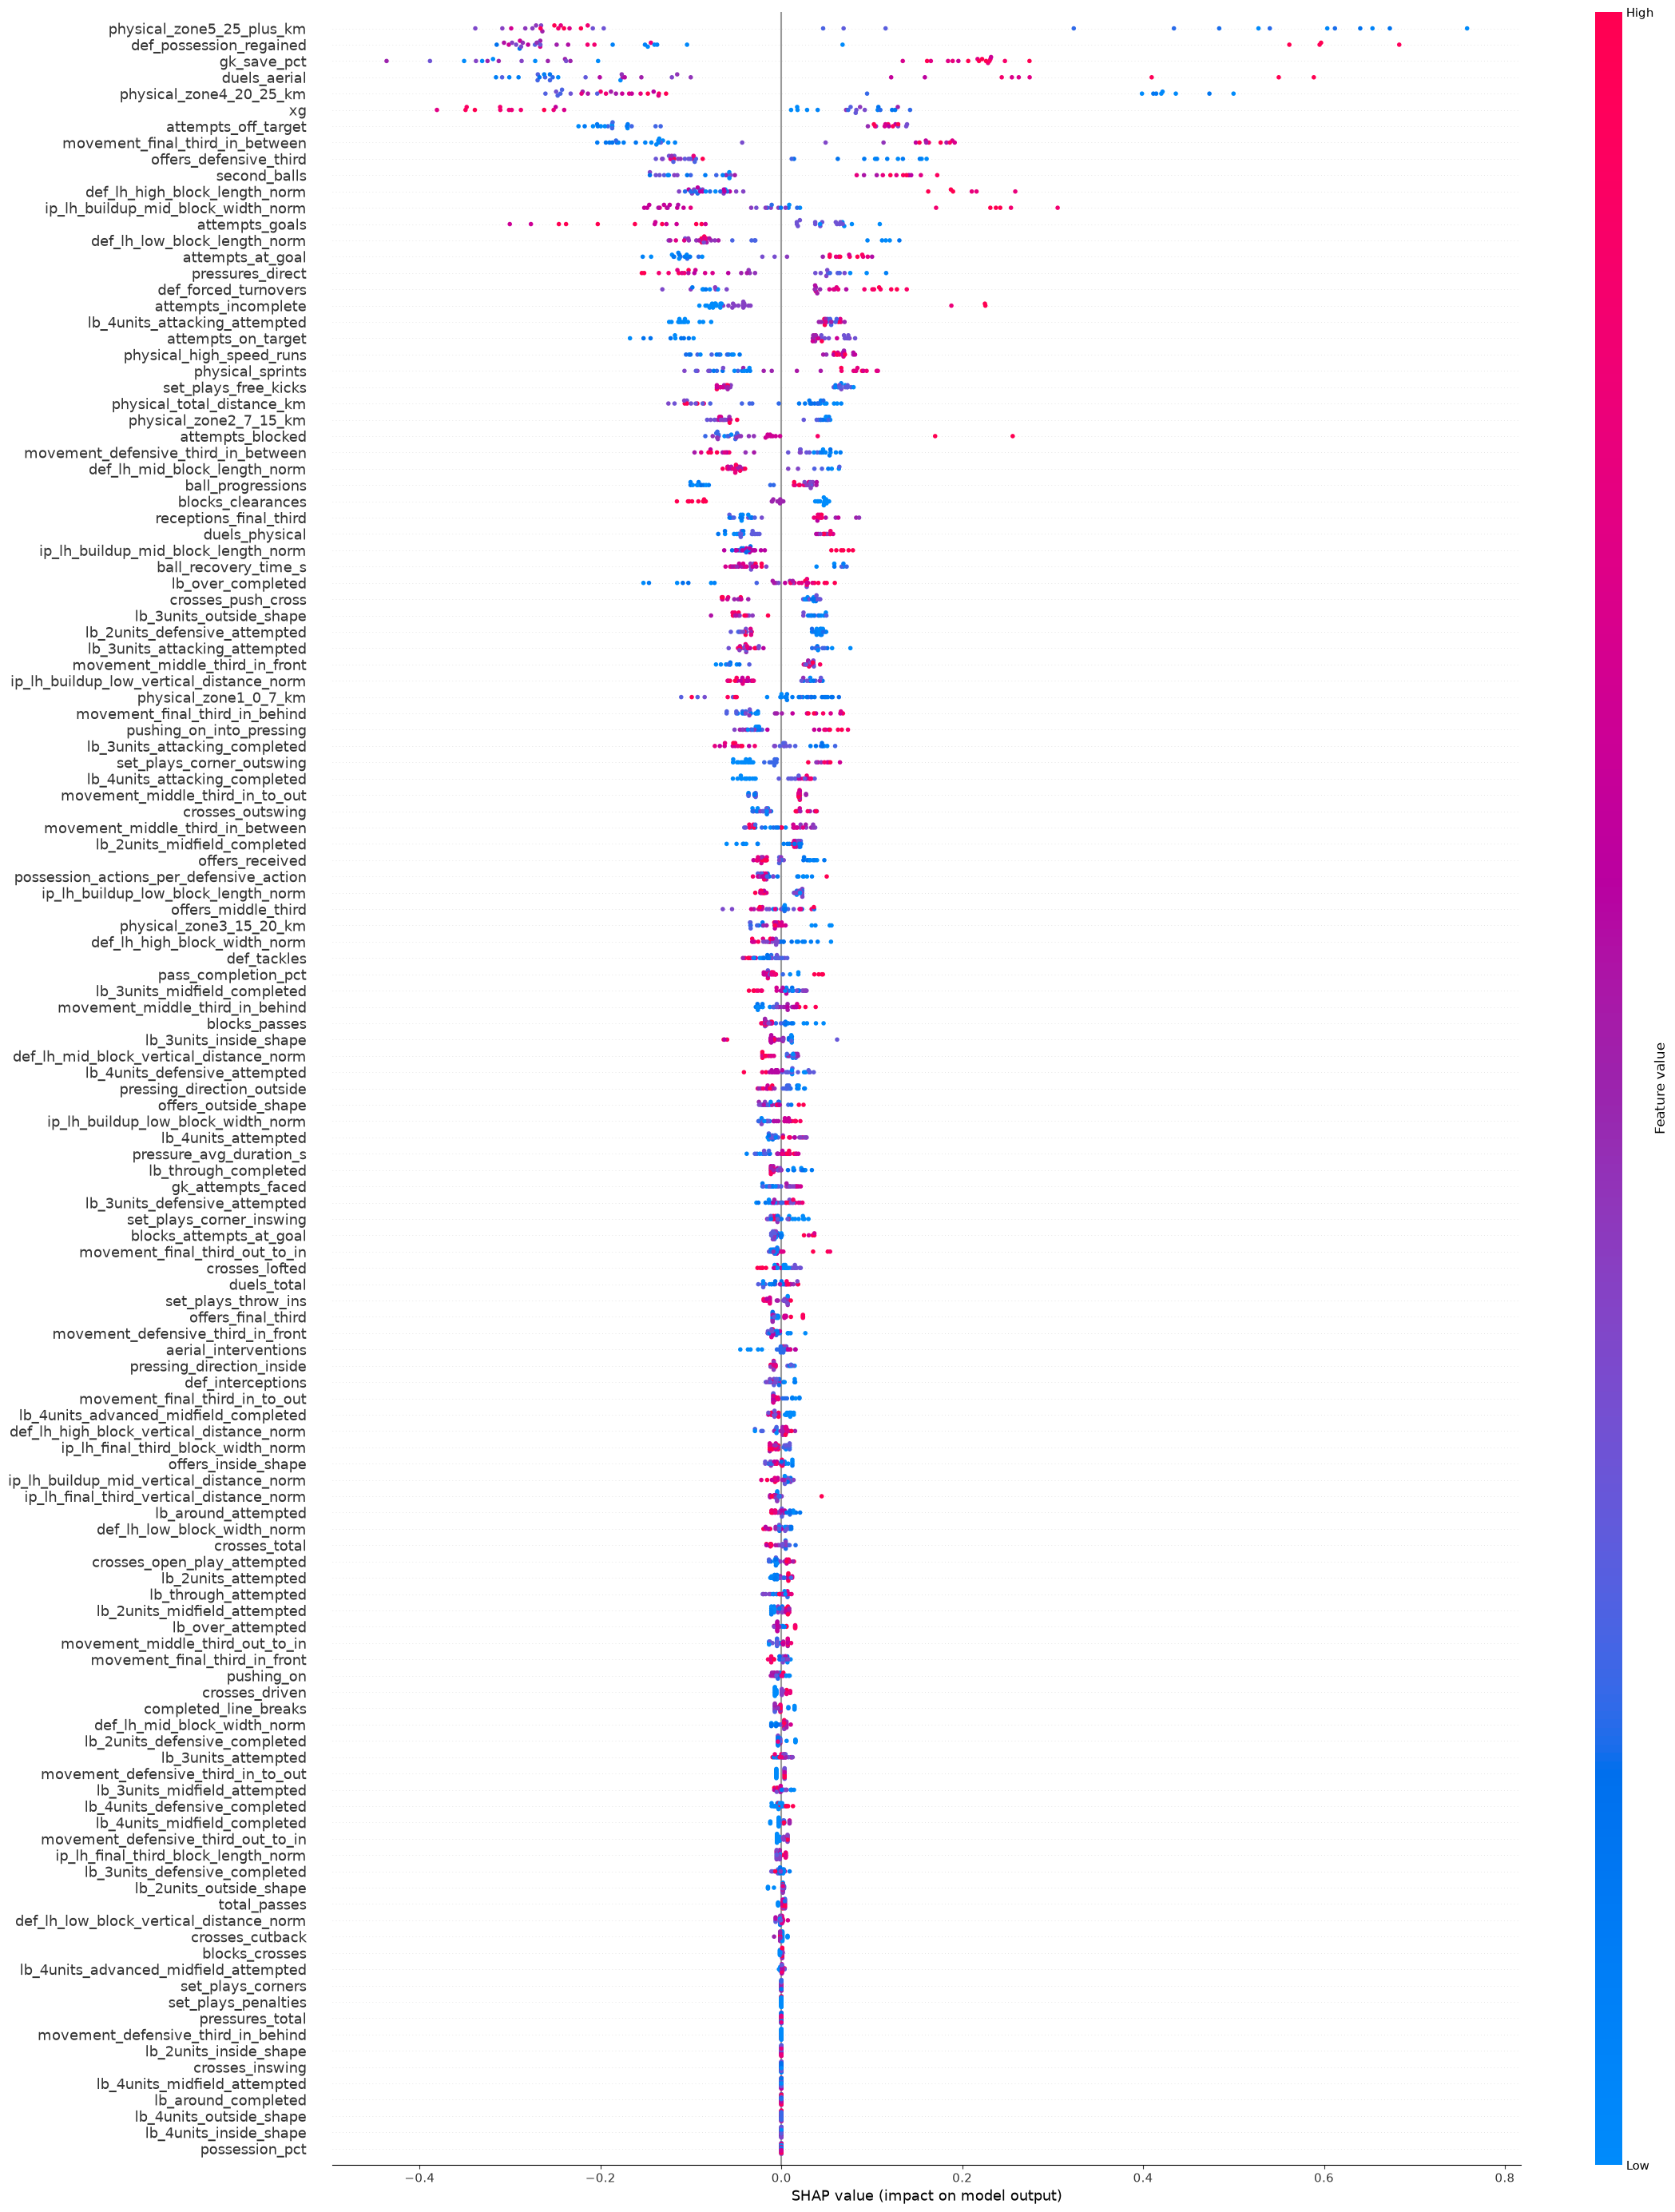

In [6]:
shap.plots.beeswarm(
    shap_values[:, :, 1],
    max_display=200,
    plot_size=(24, 35),
)

## Feature Importance across Match Result

In [65]:
import numpy as np
import pandas as pd

shap_array = shap_values.values

# (samples, features, classes)
class_names = ["lose", "draw", "win"]

importance_df = pd.DataFrame({
    class_names[i]: np.abs(shap_array[:, :, i]).mean(axis=0)
    for i in range(len(class_names))
}, index=X_test.columns)

# Overall importance across the three classes
importance_df["overall"] = importance_df[
    ["lose", "draw", "win"]
].mean(axis=1)

importance_df = importance_df.sort_values(
    "overall",
    ascending=False
)

importance_df.head(50)

,lose,draw,win,overall
attempts_goals,0.350347,0.177877,1.191072,0.573098
gk_save_pct,0.873745,0.377478,0.272684,0.507969
xg,0.589289,0.076464,0.523449,0.396401
total_passes,0.302920,0.003530,0.319447,0.208632
gk_attempts_faced,0.063074,0.102022,0.318467,0.161187
physical_zone1_0_7_km,0.305600,0.030635,0.047895,0.128043
pressures_direct,0.255267,0.106310,0.015572,0.125716
crosses_outswing,0.051897,0.008001,0.315222,0.125040
physical_zone5_25_plus_km,0.001444,0.346946,0.013197,0.120529
ball_recovery_time_s,0.132784,0.203161,0.005558,0.113834
